# Chapter 16 — Example 16.2
## Simplified DQN with Neural Network (numpy)

Implements a minimal Deep Q-Network (MLP 4→16→16→4) using only numpy.

**Book:** *Synthesis of Four-Bar Mechanisms with AI*

## 1. Q-Network Architecture

In [14]:
from numpy import *
from numpy.random import seed, randn

def relu(x): return maximum(0, x)
def forward(params, x):
    W1, b1, W2, b2, W3, b3 = params
    return W3 @ relu(W2 @ relu(W1 @ x + b1) + b2) + b3

def init_params(seed_val=0):
    seed(seed_val); s=0.1
    return [s*randn(16,4), zeros(16), s*randn(16,16), zeros(16), s*randn(4,16), zeros(4)]

print('Q-Network: 4→16→16→4  Parameters:', 4*16+16+16*16+16+16*4+4)

Q-Network: 4→16→16→4  Parameters: 420


## 2. Environment

In [15]:
def fk(a, b, c, d, n=40):
    th2 = linspace(0, 2*pi, n)
    return a*cos(th2)+b*cos(th2*0.9+0.3), a*sin(th2)+b*sin(th2*0.9+0.3)

X_obj, Y_obj = fk(1.0, 2.5, 2.0, 2.8)

def reward(state):
    a, b, c, d = state
    X, Y = fk(a, b, c, d)
    return -mean(sqrt((X-X_obj)**2 + (Y-Y_obj)**2))

D_MIN, D_MAX, DELTA = 0.5, 4.0, 0.1
ACTIONS = [array([DELTA,0,0,0]), array([-DELTA,0,0,0]),
           array([0,DELTA,0,0]), array([0,-DELTA,0,0])]

## 3. DQN Training

In [16]:
from numpy.random import seed, uniform, randint, random as rand_val

# Ensure environment variables exist if the previous cell was not executed
if 'D_MIN' not in globals():
    D_MIN, D_MAX, DELTA = 0.5, 4.0, 0.1
    ACTIONS = [array([DELTA,0,0,0]), array([-DELTA,0,0,0]),
               array([0,DELTA,0,0]), array([0,-DELTA,0,0])]
    def fk(a, b, c, d, n=40):
        th2 = linspace(0, 2*pi, n)
        return a*cos(th2)+b*cos(th2*0.9+0.3), a*sin(th2)+b*sin(th2*0.9+0.3)
    X_obj, Y_obj = fk(1.0, 2.5, 2.0, 2.8)
    def reward(state):
        a, b, c, d = state
        X, Y = fk(a, b, c, d)
        return -mean(sqrt((X-X_obj)**2 + (Y-Y_obj)**2))

seed(42)
params = init_params(42); t_params = init_params(42)
lr=0.001; gamma=0.9; eps=1.0; losses=[]; rewards=[]

for step in range(1000):
    s = uniform(D_MIN, D_MAX, 4)
    # Forward neural network step-by-step to store activations needed for gradient updates
    W1, b1, W2, b2, W3, b3 = params
    a1 = relu(W1 @ s + b1)
    a2 = relu(W2 @ a1 + b2)
    q_vals = W3 @ a2 + b3

    act = randint(0,4) if rand_val()<eps else int(argmax(q_vals))
    s2 = clip(s+ACTIONS[act], D_MIN, D_MAX)
    r = reward(s2)
    rewards.append(r)

    q2 = forward(t_params, s2)
    # Avoid collisions using numpy's amax explicitly on the q2 array
    target = r + gamma*amax(q2)
    err = target - q_vals[act]
    losses.append(err**2)

    # Gradient with respect to the last layer (W3, b3)
    # dL/dW3[act, :] = -2 * err * a2
    # dL/db3[act] = -2 * err
    # Apply gradient descent on W3 and b3:
    params[4][act, :] += lr * err * a2
    params[5][act] += lr * err

    # Avoid variable name collisions with Python's built-in max using a safe inline conditional structure
    next_eps = eps * 0.995
    eps = 0.05 if 0.05 > next_eps else next_eps
    if step%50==0: t_params = [p.copy() for p in params]

print(f'Mean Loss (last 100): {mean(losses[-100:]):.6f}')
print(f'Mean Reward (last 100): {mean(rewards[-100:]):.4f}')

Mean Loss (last 100): 2.563392
Mean Reward (last 100): -1.3830


## 4. Loss Curve

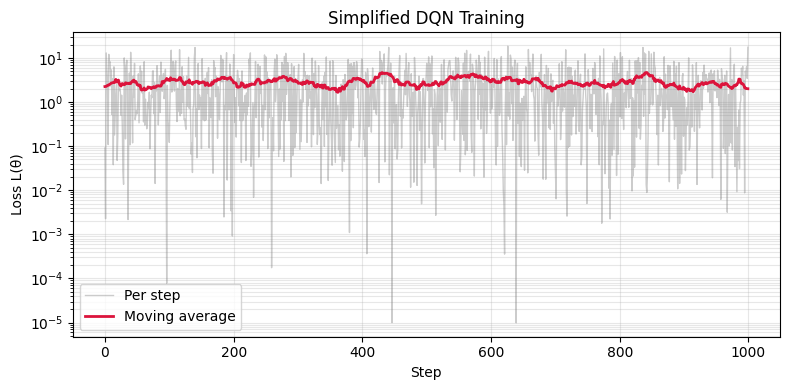

In [17]:
import matplotlib.pyplot as plt

smooth = convolve(losses, ones(30)/30, mode='same')
plt.figure(figsize=(8,4))
plt.semilogy(losses, alpha=0.4, color='gray', lw=1, label='Per step')
plt.semilogy(smooth, color='crimson', lw=2, label='Moving average')
plt.xlabel('Step'); plt.ylabel('Loss L(θ)')
plt.title('Simplified DQN Training'); plt.legend(); plt.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()